# Forecast Data Extraction Report
## Comprehensive Documentation of Swell and Wind Forecast Models

This notebook provides detailed documentation of all forecast models used in the swell and weather forecast extraction pipelines.

**Contents:**
1. **Swell Forecast Models** - Wave and swell data sources
2. **Wind Forecast Models** - Atmospheric wind data sources  
3. **Data Processing Methods** - Variable transformations
4. **Results Visualization** - Model comparison plots

---

In [1]:
# Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = [14, 8]
plt.rcParams['font.size'] = 11
print("Libraries loaded successfully!")

Libraries loaded successfully!


---
# Section 1: Swell Forecast Models

The swell forecast extractor retrieves wave and swell data from two main sources:
1. **Open-Meteo Marine API** - Multiple global wave models
2. **CDIP (Coastal Data Information Program)** - California coastal data

---
## 1.1 Open-Meteo Marine API Models

### API Endpoint
```
https://marine-api.open-meteo.com/v1/marine
```

### Common Parameters
- `latitude`, `longitude`: Target coordinates
- `hourly`: Variables to retrieve
- `timezone`: Local timezone or 'auto'
- `cell_selection`: 'sea' for ocean grid cells
- `models`: Specific model to query

In [2]:
# Swell Model Configuration Summary
swell_models = {
    'mfwam': {
        'Display Name': 'MeteoFrance MFWAM',
        'Organization': 'Météo-France',
        'Resolution': '~8 km',
        'Forecast Days': 10,
        'Coverage': 'Global',
        'Swell Partitions': 'Primary + Secondary',
        'Data Source': 'Copernicus Marine Service'
    },
    'ecmwf_wam': {
        'Display Name': 'ECMWF WAM 9km',
        'Organization': 'ECMWF',
        'Resolution': '~9 km',
        'Forecast Days': 15,
        'Coverage': 'Global',
        'Swell Partitions': 'Primary only',
        'Data Source': 'ECMWF Open Data'
    },
    'ecmwf_wam025': {
        'Display Name': 'ECMWF WAM 25km',
        'Organization': 'ECMWF',
        'Resolution': '~25 km',
        'Forecast Days': 15,
        'Coverage': 'Global',
        'Swell Partitions': 'Primary only',
        'Data Source': 'ECMWF Open Data'
    },
    'gfs_wave025': {
        'Display Name': 'GFS Wave 25km',
        'Organization': 'NOAA/NCEP',
        'Resolution': '~25 km',
        'Forecast Days': 16,
        'Coverage': 'Global',
        'Swell Partitions': 'Primary + Secondary + Tertiary',
        'Data Source': 'NOAA NOMADS'
    },
    'gfs_wave016': {
        'Display Name': 'GFS Wave 16km',
        'Organization': 'NOAA/NCEP',
        'Resolution': '~16 km',
        'Forecast Days': 16,
        'Coverage': 'Global',
        'Swell Partitions': 'Primary + Secondary + Tertiary',
        'Data Source': 'NOAA NOMADS'
    },
    'dwd_ewam': {
        'Display Name': 'DWD EWAM',
        'Organization': 'DWD (Germany)',
        'Resolution': '~5 km',
        'Forecast Days': 8,
        'Coverage': 'European Waters',
        'Swell Partitions': 'Primary only',
        'Data Source': 'DWD Open Data'
    },
    'dwd_gwam': {
        'Display Name': 'DWD GWAM',
        'Organization': 'DWD (Germany)',
        'Resolution': '~25 km',
        'Forecast Days': 4,
        'Coverage': 'Global',
        'Swell Partitions': 'Primary only',
        'Data Source': 'DWD Open Data'
    }
}

df = pd.DataFrame(swell_models).T
df.index.name = 'model_key'
print("="*100)
print("OPEN-METEO MARINE API - SWELL MODELS SUMMARY")
print("="*100)
display(df)

OPEN-METEO MARINE API - SWELL MODELS SUMMARY


,Display Name,Organization,Resolution,Forecast Days,Coverage,Swell Partitions,Data Source
model_key,,,,,,,
mfwam,MeteoFrance MFWAM,Météo-France,~8 km,10,Global,Primary + Secondary,Copernicus Marine Service
ecmwf_wam,ECMWF WAM 9km,ECMWF,~9 km,15,Global,Primary only,ECMWF Open Data
ecmwf_wam025,ECMWF WAM 25km,ECMWF,~25 km,15,Global,Primary only,ECMWF Open Data
gfs_wave025,GFS Wave 25km,NOAA/NCEP,~25 km,16,Global,Primary + Secondary + Tertiary,NOAA NOMADS
gfs_wave016,GFS Wave 16km,NOAA/NCEP,~16 km,16,Global,Primary + Secondary + Tertiary,NOAA NOMADS
dwd_ewam,DWD EWAM,DWD (Germany),~5 km,8,European Waters,Primary only,DWD Open Data
dwd_gwam,DWD GWAM,DWD (Germany),~25 km,4,Global,Primary only,DWD Open Data


---
## 1.1.1 MeteoFrance MFWAM (Météo-France Wave Model)

### Overview
MFWAM is a third-generation spectral wave model operated by Météo-France, distributed through Copernicus Marine Service.

### Model Specifications
| Parameter | Value |
|-----------|-------|
| **Model Type** | Third-generation spectral wave model |
| **Base Model** | WAM (WAve Model) |
| **Spatial Resolution** | 0.083° (~8-9 km at equator) |
| **Temporal Resolution** | 3-hourly |
| **Forecast Horizon** | 10 days |
| **Update Frequency** | Twice daily (00Z, 12Z) |
| **Atmospheric Forcing** | ARPEGE global model |

### Physics
MFWAM resolves the wave energy spectrum across:
- **24 directions** (15° directional resolution)
- **30 frequencies** (0.035 to 0.58 Hz)

The model solves the **wave action balance equation**:
```
∂N/∂t + ∇·(cg·N) = Sin + Snl + Sds + Sbot
```
Where:
- N = Wave action density spectrum
- cg = Group velocity
- Sin = Wind input source term
- Snl = Nonlinear wave-wave interactions
- Sds = Whitecapping dissipation
- Sbot = Bottom friction

### Swell Partitioning
MFWAM provides **primary and secondary swell** through spectral partitioning using a watershed algorithm on the 2D wave spectrum.

### Variables Extracted
| Variable | API Parameter | Unit |
|----------|---------------|------|
| Combined Wave Height | `wave_height` | m |
| Combined Wave Period | `wave_period` | s |
| Combined Wave Direction | `wave_direction` | ° |
| Wind Wave Height | `wind_wave_height` | m |
| Primary Swell Height | `swell_wave_height` | m |
| Primary Swell Period | `swell_wave_period` | s |
| Primary Swell Direction | `swell_wave_direction` | ° |
| Secondary Swell Height | `secondary_swell_wave_height` | m |
| Secondary Swell Period | `secondary_swell_wave_period` | s |
| Secondary Swell Direction | `secondary_swell_wave_direction` | ° |

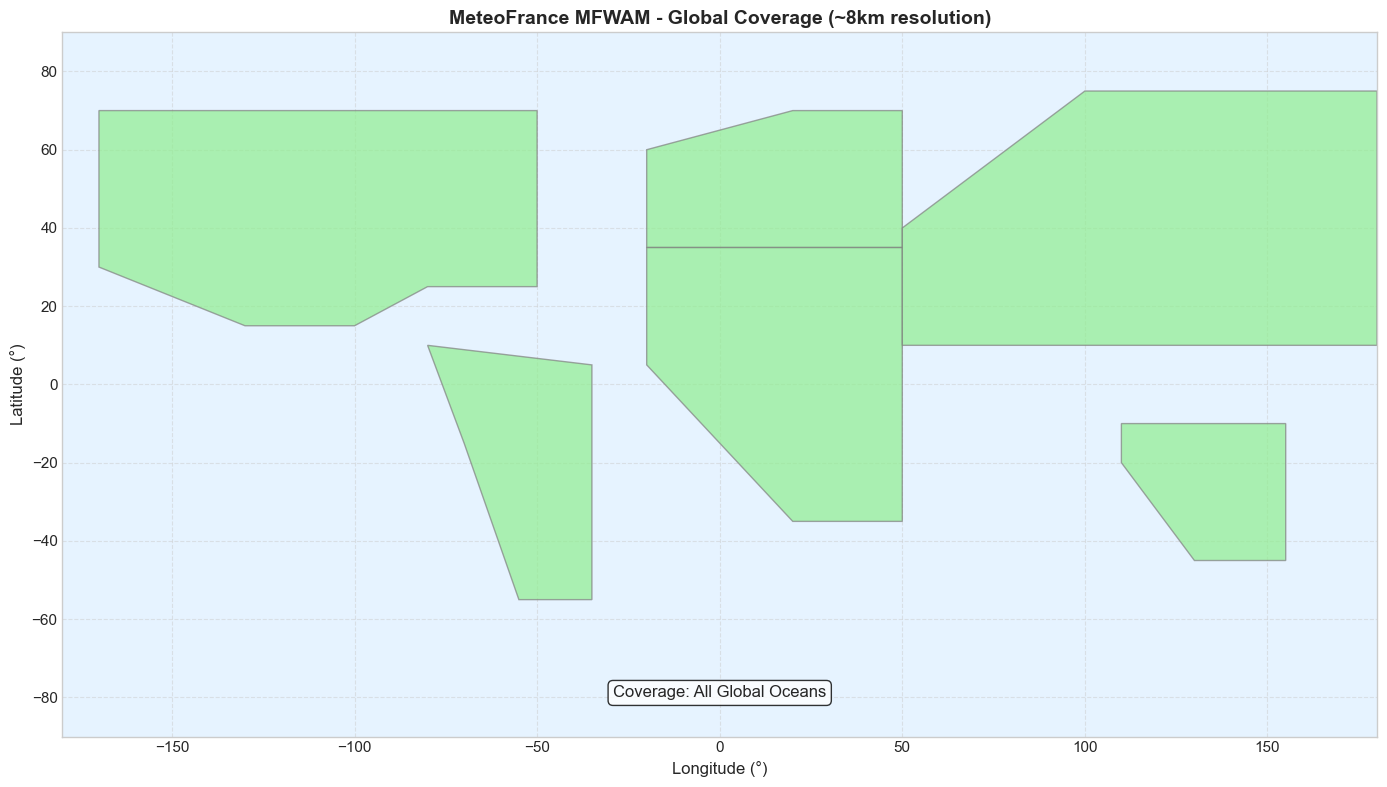

In [3]:
def plot_model_coverage(title, region_bounds=None, highlight_color='yellow'):
    """Plot model coverage area."""
    fig, ax = plt.subplots(figsize=(14, 8))
    
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_facecolor('#E6F3FF')  # Ocean blue
    
    # Simplified continents
    continents = [
        # North America
        ([-170, -170, -50, -50, -80, -100, -130, -170], [30, 70, 70, 25, 25, 15, 15, 30]),
        # South America
        ([-80, -35, -35, -55, -70, -80], [10, 5, -55, -55, -15, 10]),
        # Europe
        ([-20, 50, 50, 20, -20, -20], [35, 35, 70, 70, 60, 35]),
        # Africa
        ([-20, 50, 50, 20, -20, -20], [35, 35, -35, -35, 5, 35]),
        # Asia
        ([50, 180, 180, 100, 50], [10, 10, 75, 75, 40]),
        # Australia
        ([110, 155, 155, 130, 110], [-10, -10, -45, -45, -20])
    ]
    
    for x, y in continents:
        ax.fill(x, y, color='#90EE90', edgecolor='gray', alpha=0.7)
    
    if region_bounds:
        rect = mpatches.Rectangle(
            (region_bounds[0], region_bounds[2]),
            region_bounds[1] - region_bounds[0],
            region_bounds[3] - region_bounds[2],
            fill=True, facecolor=highlight_color, edgecolor='red',
            alpha=0.3, linewidth=2
        )
        ax.add_patch(rect)
    
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel('Longitude (°)', fontsize=12)
    ax.set_ylabel('Latitude (°)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    return fig, ax

# MFWAM global coverage
fig, ax = plot_model_coverage('MeteoFrance MFWAM - Global Coverage (~8km resolution)')
ax.text(0, -80, 'Coverage: All Global Oceans', ha='center', fontsize=12, 
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()

---
## 1.1.2 ECMWF WAM (Wave Model)

### Overview
The ECMWF WAM is operated by the European Centre for Medium-Range Weather Forecasts. It is the original third-generation wave model and the basis for many other wave models.

### Model Specifications
| Parameter | WAM 9km | WAM 25km |
|-----------|---------|----------|
| **Spatial Resolution** | 0.083° (~9 km) | 0.25° (~25 km) |
| **Temporal Resolution** | 3-hourly | 3-hourly |
| **Forecast Horizon** | 15 days | 15 days |
| **Update Frequency** | 4x daily | 4x daily |
| **Atmospheric Forcing** | IFS (Integrated Forecasting System) |

### Key Features
- **Two-way coupling**: Wave-atmosphere interaction in IFS
- **ST4 physics**: Advanced wind input and dissipation terms
- **Spectral resolution**: 24 directions × 30 frequencies

### Significant Wave Height Calculation
$$H_s = 4\sqrt{m_0} = 4\sqrt{\int E(f,\theta) \, d\theta \, df}$$

### Limitations
- **No swell partitioning**: Only provides primary swell (total swell component)
- Cannot distinguish multiple swell systems

---
## 1.1.3 NOAA GFS Wave Model (WAVEWATCH III)

### Overview
The GFS Wave model is NOAA's operational global wave forecasting system, based on WAVEWATCH III. It is **unique** in providing **tertiary swell** partitions.

### Model Specifications
| Parameter | GFS Wave 16km | GFS Wave 25km |
|-----------|---------------|---------------|
| **Spatial Resolution** | 0.16° (~16 km) | 0.25° (~25 km) |
| **Temporal Resolution** | 3-hourly | 3-hourly |
| **Forecast Horizon** | 16 days | 16 days |
| **Swell Partitions** | 3 (Primary, Secondary, Tertiary) |
| **Atmospheric Forcing** | GFS atmospheric model |

### WAVEWATCH III Framework
1. **Spectral Partitioning Algorithm**
   - Identifies up to 3 distinct swell systems
   - Uses watershed algorithm on 2D frequency-direction spectrum
   - Separates wind-sea from swell based on wave age

2. **Wave Age Criterion**
   ```
   cp/U10 > 1.2 → Swell
   ```
   Where cp = phase velocity, U10 = 10m wind speed

### Swell Partitioning Example
For a complex California sea state:
- **Primary Swell**: Long-period NW swell from North Pacific storm (17s, 280°)
- **Secondary Swell**: SW swell from Southern Hemisphere (14s, 210°)
- **Tertiary Swell**: Short-period local wind swell (8s, 310°)

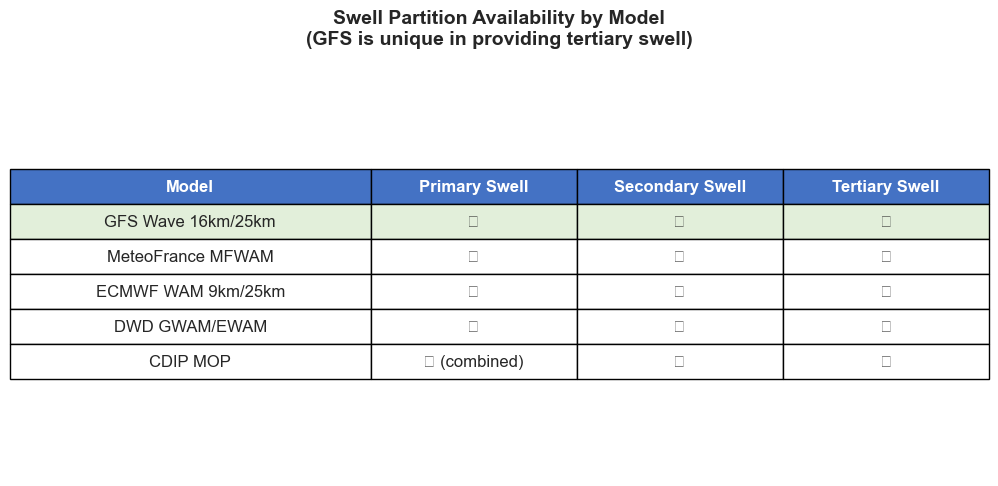

In [4]:
# Swell Partition Availability Comparison
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

table_data = [
    ['Model', 'Primary Swell', 'Secondary Swell', 'Tertiary Swell'],
    ['GFS Wave 16km/25km', '✓', '✓', '✓'],
    ['MeteoFrance MFWAM', '✓', '✓', '✗'],
    ['ECMWF WAM 9km/25km', '✓', '✗', '✗'],
    ['DWD GWAM/EWAM', '✓', '✗', '✗'],
    ['CDIP MOP', '✓ (combined)', '✗', '✗'],
]

table = ax.table(cellText=table_data, loc='center', cellLoc='center',
                  colWidths=[0.35, 0.2, 0.2, 0.2])
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2.0)

# Style header
for i in range(4):
    table[(0, i)].set_facecolor('#4472C4')
    table[(0, i)].set_text_props(color='white', fontweight='bold')

# Highlight GFS row
for i in range(4):
    table[(1, i)].set_facecolor('#E2EFDA')

ax.set_title('Swell Partition Availability by Model\n(GFS is unique in providing tertiary swell)', 
             fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

---
## 1.1.4 DWD Wave Models (EWAM & GWAM)

### DWD EWAM (European Wave Model)
| Parameter | Value |
|-----------|-------|
| **Spatial Resolution** | ~5 km |
| **Temporal Resolution** | 1-hourly |
| **Forecast Horizon** | 8 days |
| **Coverage** | European waters (Atlantic, North Sea, Baltic, Mediterranean) |
| **Atmospheric Forcing** | ICON-EU |

### DWD GWAM (Global Wave Model)
| Parameter | Value |
|-----------|-------|
| **Spatial Resolution** | ~25 km |
| **Temporal Resolution** | 3-hourly |
| **Forecast Horizon** | 4 days (shortest of all models) |
| **Coverage** | Global |
| **Atmospheric Forcing** | ICON Global |

### Key Points
- Based on WAM cycle 4.6
- EWAM excellent for European coastal applications
- GWAM has the **shortest forecast horizon** (4 days)

---
## 1.2 CDIP Data Sources (Coastal Data Information Program)

CDIP is operated by Scripps Institution of Oceanography, providing high-quality wave data for the California coast.

### 1.2.1 MOP California Grid Forecast

| Parameter | Value |
|-----------|-------|
| **Data Access** | THREDDS OPeNDAP |
| **URL** | `https://thredds.cdip.ucsd.edu/thredds/dodsC/cdip/model/MOP_grids/CA_0.01_forecast.nc` |
| **Spatial Resolution** | 0.01° (~1 km) |
| **Coverage** | California coast (30°N - 48°N, -130°W - -115°W) |
| **Forecast Horizon** | ~7 days |

### Model Chain
1. **Global forcing**: ECMWF wave forecasts
2. **Regional model**: WAVEWATCH III at ~5 km
3. **Nearshore model**: SWAN at ~1 km
4. **Data assimilation**: CDIP buoy observations

### Variables
| Variable | NetCDF Name | Unit |
|----------|-------------|------|
| Significant Wave Height | `waveHs` | m |
| Peak Period | `waveTp` | s |
| Peak Direction | `waveDp` | ° |
| Average Period | `waveTa` | s |

### Grid Point Selection Algorithm
1. Find nearest grid point by lat/lon
2. Check if data exists (not NaN)
3. If NaN, search outward for closest valid cell
4. Report distance from request to actual grid point

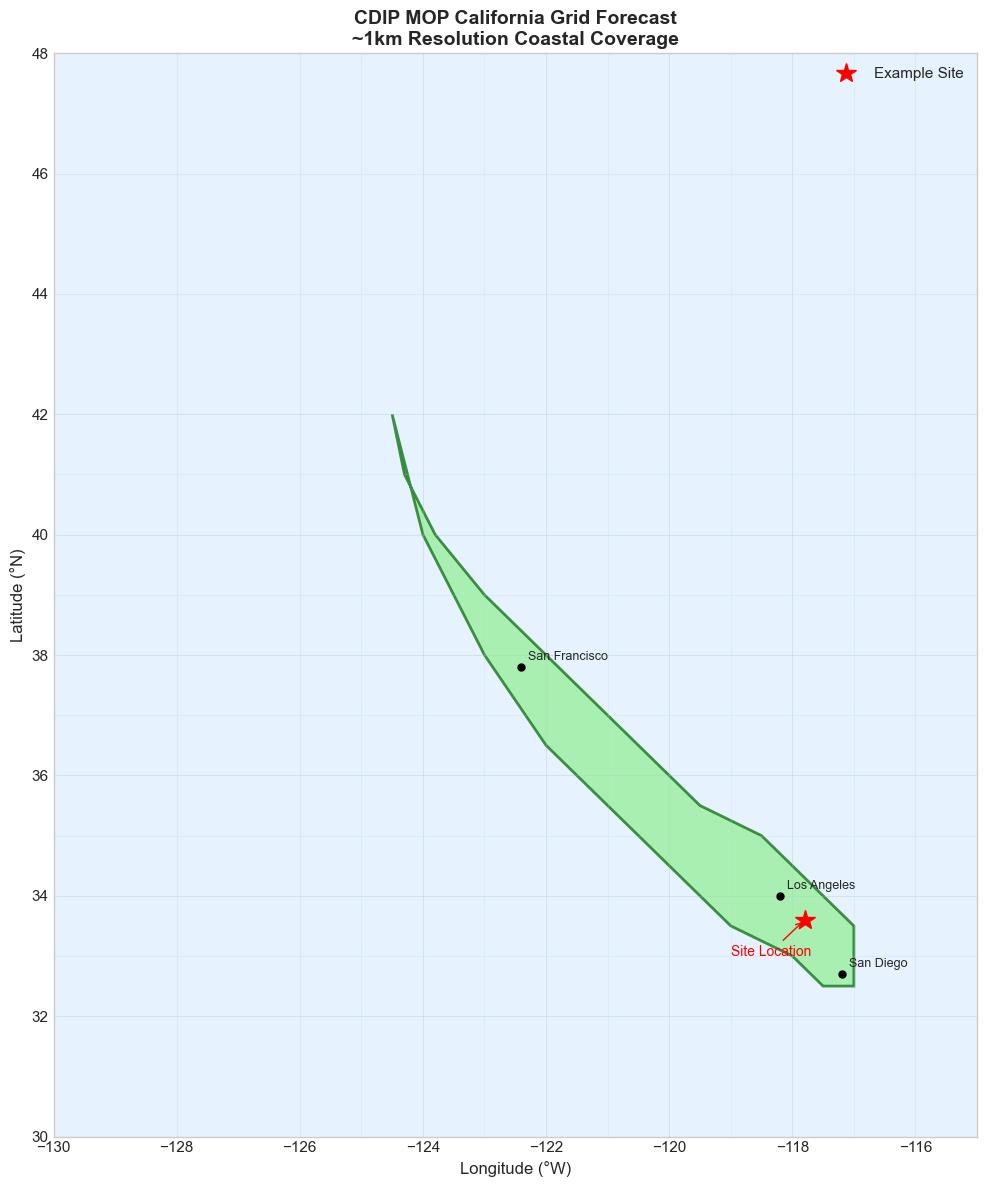

In [5]:
# CDIP MOP California coverage
fig, ax = plt.subplots(figsize=(10, 12))

# California outline
ca_lon = [-124.5, -124.3, -123.8, -123.0, -122.5, -122.0, -121.5, -121.0, 
          -120.5, -120.0, -119.5, -118.5, -118.0, -117.5, -117.0, -117.0,
          -117.5, -118.0, -119.0, -120.0, -121.0, -122.0, -123.0, -124.0, -124.5]
ca_lat = [42.0, 41.0, 40.0, 39.0, 38.5, 38.0, 37.5, 37.0,
          36.5, 36.0, 35.5, 35.0, 34.5, 34.0, 33.5, 32.5,
          32.5, 33.0, 33.5, 34.5, 35.5, 36.5, 38.0, 40.0, 42.0]

ax.fill(ca_lon, ca_lat, color='#90EE90', edgecolor='darkgreen', linewidth=2, alpha=0.7)
ax.set_xlim(-130, -115)
ax.set_ylim(30, 48)
ax.set_facecolor('#E6F3FF')

# Grid lines
for lon in np.arange(-125, -116, 1):
    ax.axvline(lon, color='lightblue', alpha=0.3, linewidth=0.5)
for lat in np.arange(32, 43, 1):
    ax.axhline(lat, color='lightblue', alpha=0.3, linewidth=0.5)

# Example site
ax.plot(-117.8, 33.6, 'r*', markersize=15, label='Example Site')
ax.annotate('Site Location', xy=(-117.8, 33.6), xytext=(-119, 33),
            arrowprops=dict(arrowstyle='->', color='red'), fontsize=10, color='red')

# Cities
cities = {'San Francisco': (-122.4, 37.8), 'Los Angeles': (-118.2, 34.0),
          'San Diego': (-117.2, 32.7)}
for city, (lon, lat) in cities.items():
    ax.plot(lon, lat, 'ko', markersize=5)
    ax.annotate(city, xy=(lon, lat), xytext=(5, 5), textcoords='offset points', fontsize=9)

ax.set_xlabel('Longitude (°W)', fontsize=12)
ax.set_ylabel('Latitude (°N)', fontsize=12)
ax.set_title('CDIP MOP California Grid Forecast\n~1km Resolution Coastal Coverage', fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
### 1.2.2 CDIP Buoy Station Forecasts

Individual CDIP buoys provide MOP-based forecasts at their locations, combining model forecasts with local observations.

| Parameter | Value |
|-----------|-------|
| **Format** | NetCDF via OPeNDAP |
| **URL Pattern** | `https://thredds.cdip.ucsd.edu/.../BP{station_id}_forecast.nc` |
| **Forecast Horizon** | 7-10 days |
| **Resolution** | Point forecast at buoy location |

### Active Buoy Discovery
The extractor dynamically discovers active CDIP buoys using ERDDAP:
```python
url = "https://erddap.cdip.ucsd.edu/erddap/tabledap/wave_agg.csv"
query = "?station_id,metaStationName,latitude,longitude,time&orderByMax(station_id,time)"
```

### Station Selection Algorithm
1. Query ERDDAP for stations with recent data (within 7 days)
2. Calculate Haversine distance to each active buoy
3. Select N closest buoys (default: 2)
4. Fetch forecast data for each selected buoy

### Haversine Distance Formula
```
d = 2R × arcsin(√[sin²((φ₂-φ₁)/2) + cos(φ₁)cos(φ₂)sin²((λ₂-λ₁)/2)])
```
Where R = 6371 km (Earth's radius)

### Output Columns for Buoy Data
| Column | Description |
|--------|-------------|
| `buoy_id` | CDIP station ID (e.g., "071") |
| `buoy_name` | Station name (e.g., "Harvest") |
| `buoy_distance_km` | Distance from site to buoy |

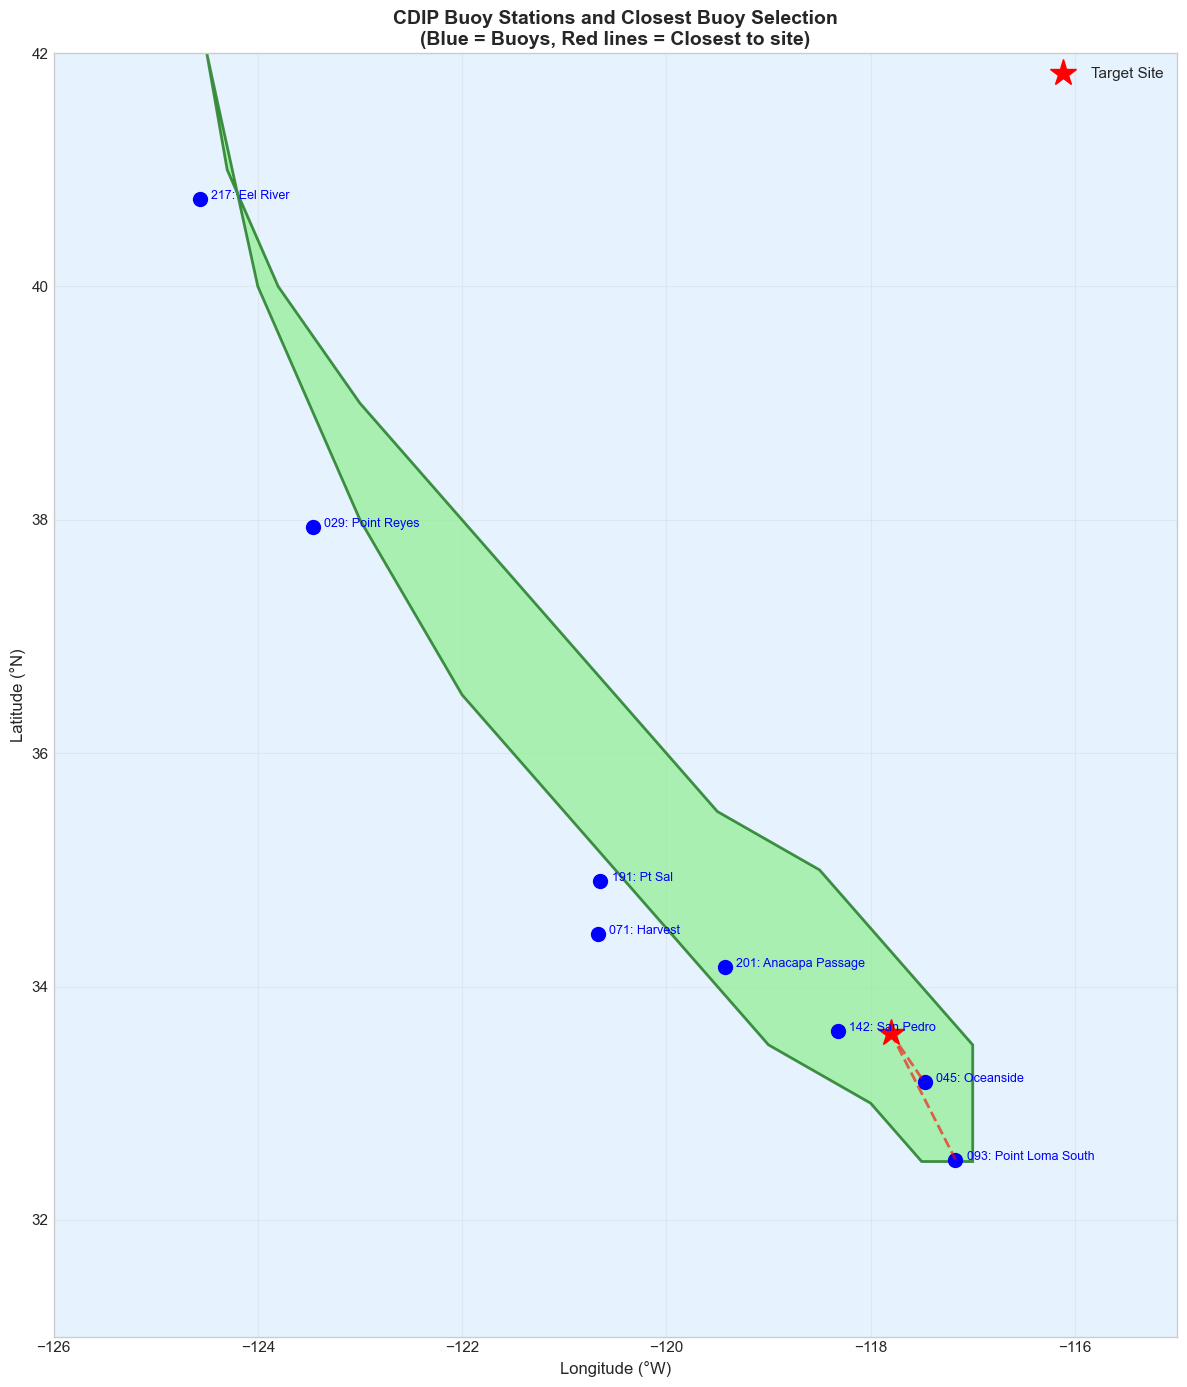


CDIP Buoy Stations (Sample):


,name,lat,lon
station_id,,,
029,Point Reyes,37.936,-123.464
071,Harvest,34.452,-120.673
045,Oceanside,33.178,-117.472
093,Point Loma South,32.517,-117.169
142,San Pedro,33.618,-118.317
191,Pt Sal,34.903,-120.645
201,Anacapa Passage,34.171,-119.428
217,Eel River,40.749,-124.563


In [6]:
# CDIP Buoy locations example
cdip_buoys = {
    '029': {'name': 'Point Reyes', 'lat': 37.936, 'lon': -123.464},
    '071': {'name': 'Harvest', 'lat': 34.452, 'lon': -120.673},
    '045': {'name': 'Oceanside', 'lat': 33.178, 'lon': -117.472},
    '093': {'name': 'Point Loma South', 'lat': 32.517, 'lon': -117.169},
    '142': {'name': 'San Pedro', 'lat': 33.618, 'lon': -118.317},
    '191': {'name': 'Pt Sal', 'lat': 34.903, 'lon': -120.645},
    '201': {'name': 'Anacapa Passage', 'lat': 34.171, 'lon': -119.428},
    '217': {'name': 'Eel River', 'lat': 40.749, 'lon': -124.563},
}

fig, ax = plt.subplots(figsize=(12, 14))
ax.fill(ca_lon, ca_lat, color='#90EE90', edgecolor='darkgreen', linewidth=2, alpha=0.7)
ax.set_xlim(-126, -115)
ax.set_ylim(31, 42)
ax.set_facecolor('#E6F3FF')

# Plot buoys
for stn_id, info in cdip_buoys.items():
    ax.plot(info['lon'], info['lat'], 'bo', markersize=10)
    ax.annotate(f"{stn_id}: {info['name']}", xy=(info['lon'], info['lat']), 
                xytext=(8, 0), textcoords='offset points', fontsize=9, color='blue')

# Example site and closest buoys
site_lat, site_lon = 33.6, -117.8
ax.plot(site_lon, site_lat, 'r*', markersize=20, label='Target Site')

# Lines to closest buoys
for bid in ['045', '093']:
    binfo = cdip_buoys[bid]
    ax.plot([site_lon, binfo['lon']], [site_lat, binfo['lat']], 'r--', linewidth=2, alpha=0.6)

ax.set_xlabel('Longitude (°W)', fontsize=12)
ax.set_ylabel('Latitude (°N)', fontsize=12)
ax.set_title('CDIP Buoy Stations and Closest Buoy Selection\n(Blue = Buoys, Red lines = Closest to site)', 
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display buoy table
print("\nCDIP Buoy Stations (Sample):")
buoy_df = pd.DataFrame(cdip_buoys).T
buoy_df.index.name = 'station_id'
display(buoy_df)

---
# Section 2: Wind Forecast Models

The weather forecast extractor retrieves wind data from multiple atmospheric models via the Open-Meteo API.

### API Endpoint
```
https://api.open-meteo.com/v1/{endpoint}
```

### Variables Extracted
| Variable | API Parameter | Unit |
|----------|---------------|------|
| Wind Speed | `wind_speed_10m` | km/h |
| Wind Direction | `wind_direction_10m` | ° (from) |
| Wind Gusts | `wind_gusts_10m` | km/h |

---

In [ ]:
# Wind Model Configuration Summary
wind_models = {
    'gfs_seamless': {'Display Name': 'GFS Seamless', 'Organization': 'NOAA/NCEP', 
                     'Resolution': '~13-25 km', 'Forecast Days': 16, 'Coverage': 'Global'},
    'gfs_global': {'Display Name': 'GFS 22km', 'Organization': 'NOAA/NCEP', 
                   'Resolution': '~25 km', 'Forecast Days': 16, 'Coverage': 'Global'},
    'hrrr_conus': {'Display Name': 'HRRR 3km', 'Organization': 'NOAA/NCEP', 
                   'Resolution': '3 km', 'Forecast Days': 2, 'Coverage': 'Continental US'},
    'nam_conus': {'Display Name': 'NAM 5km', 'Organization': 'NOAA/NCEP', 
                  'Resolution': '~5 km', 'Forecast Days': 3, 'Coverage': 'North America'},
    'nbm_conus': {'Display Name': 'NBM', 'Organization': 'NOAA/NWS', 
                  'Resolution': '2.5 km', 'Forecast Days': 11, 'Coverage': 'Continental US'},
    'gem_hrdps_continental': {'Display Name': 'HRDPS 2.5km', 'Organization': 'ECCC (Canada)', 
                              'Resolution': '2.5 km', 'Forecast Days': 2, 'Coverage': 'Canada/Northern US'},
    'gem_global': {'Display Name': 'GEM Global', 'Organization': 'ECCC (Canada)', 
                   'Resolution': '~15 km', 'Forecast Days': 10, 'Coverage': 'Global'},
    'ecmwf_ifs04': {'Display Name': 'ECMWF IFS 9km', 'Organization': 'ECMWF', 
                    'Resolution': '~9 km', 'Forecast Days': 10, 'Coverage': 'Global'},
    'icon_global': {'Display Name': 'ICON 13km', 'Organization': 'DWD', 
                    'Resolution': '~13 km', 'Forecast Days': 8, 'Coverage': 'Global'},
    'icon_seamless': {'Display Name': 'ICON Seamless', 'Organization': 'DWD', 
                      'Resolution': '~2-13 km', 'Forecast Days': 8, 'Coverage': 'Global/EU'}
}

df = pd.DataFrame(wind_models).T
df.index.name = 'model_key'
print("="*100)
print("OPEN-METEO WEATHER API - WIND MODELS SUMMARY")
print("="*100)
display(df)

---
## 2.1 GFS (Global Forecast System)

### Overview
GFS is NOAA's primary global weather forecasting model, providing medium-range forecasts up to 16 days.

### Model Specifications
| Parameter | Value |
|-----------|-------|
| **Organization** | NOAA/NCEP |
| **Spatial Resolution** | 0.25° (~25 km) / Seamless blends to 13km |
| **Vertical Levels** | 127 |
| **Forecast Horizon** | 16 days |
| **Update Frequency** | 4x daily (00, 06, 12, 18 UTC) |
| **Dynamical Core** | FV3 (Finite-Volume Cubed-Sphere) |

### 10-meter Wind Calculation
GFS outputs wind at 10 meters AGL using surface layer physics:
1. **Model level winds**: Computed at ~50m (lowest level)
2. **Surface layer extrapolation**: Monin-Obukhov similarity theory

$$U_{10} = U_z \frac{\ln(10/z_0)}{\ln(z/z_0)} \cdot \Psi_m^{-1}(\zeta)$$

---
## 2.2 HRRR (High-Resolution Rapid Refresh)

### Overview
HRRR is NOAA's highest-resolution operational model for the continental US, ideal for nowcasting.

### Model Specifications
| Parameter | Value |
|-----------|-------|
| **Spatial Resolution** | 3 km |
| **Vertical Levels** | 50 |
| **Forecast Horizon** | 18-48 hours |
| **Update Frequency** | Hourly |
| **Coverage** | Continental US only |

### Key Features
- **Radar data assimilation**: NEXRAD reflectivity and radial velocity
- **Surface observations**: METAR, mesonet, aircraft data
- **Hourly updates**: New forecasts every hour
- **Best for**: Short-range forecasts (0-18 hours)

---
## 2.3 NAM (North American Mesoscale)

| Parameter | Value |
|-----------|-------|
| **Parent Resolution** | 12 km |
| **CONUS Nest** | ~5 km |
| **Forecast Horizon** | 60-84 hours |
| **Coverage** | North America |

---
## 2.4 NBM (National Blend of Models)

### Overview
NBM blends multiple model outputs to provide the "best" forecast.

| Parameter | Value |
|-----------|-------|
| **Resolution** | 2.5 km |
| **Forecast Horizon** | Up to 11 days |
| **Coverage** | Continental US |

### Blending Method
- Combines GFS, NAM, HRRR, ECMWF, Canadian models
- Statistical post-processing (MOS)
- Dynamic weights based on recent performance

**Advantage**: Generally more accurate than any single model

---
## 2.5 ECMWF IFS (Integrated Forecasting System)

### Overview
Widely considered the **world's best** global weather forecasting model.

| Parameter | Value |
|-----------|-------|
| **Resolution** | ~9 km (0.1°) |
| **Vertical Levels** | 137 |
| **Model Top** | 0.01 hPa (~80 km) |
| **Forecast Horizon** | 10-15 days |

### Why ECMWF Excels
1. **4D-Var data assimilation**: Most sophisticated system
2. **Global observations**: Millions ingested daily
3. **Coupled system**: Atmosphere, ocean, waves, sea ice
4. **Research focus**: Continuous model improvement

---
## 2.6 ICON (DWD)

| Parameter | Value |
|-----------|-------|
| **Resolution** | ~13 km global, ~2 km in EU nests |
| **Grid Type** | Icosahedral (uniform coverage) |
| **Forecast Horizon** | ~8 days |

---
## 2.7 Canadian Models (GEM, HRDPS)

### GEM Global
| Parameter | Value |
|-----------|-------|
| **Resolution** | ~15 km |
| **Forecast Horizon** | 10 days |
| **Coverage** | Global |

### HRDPS
| Parameter | Value |
|-----------|-------|
| **Resolution** | 2.5 km |
| **Forecast Horizon** | 48 hours |
| **Coverage** | Canada + Northern US |
| **Strength** | Excellent for mountainous terrain |

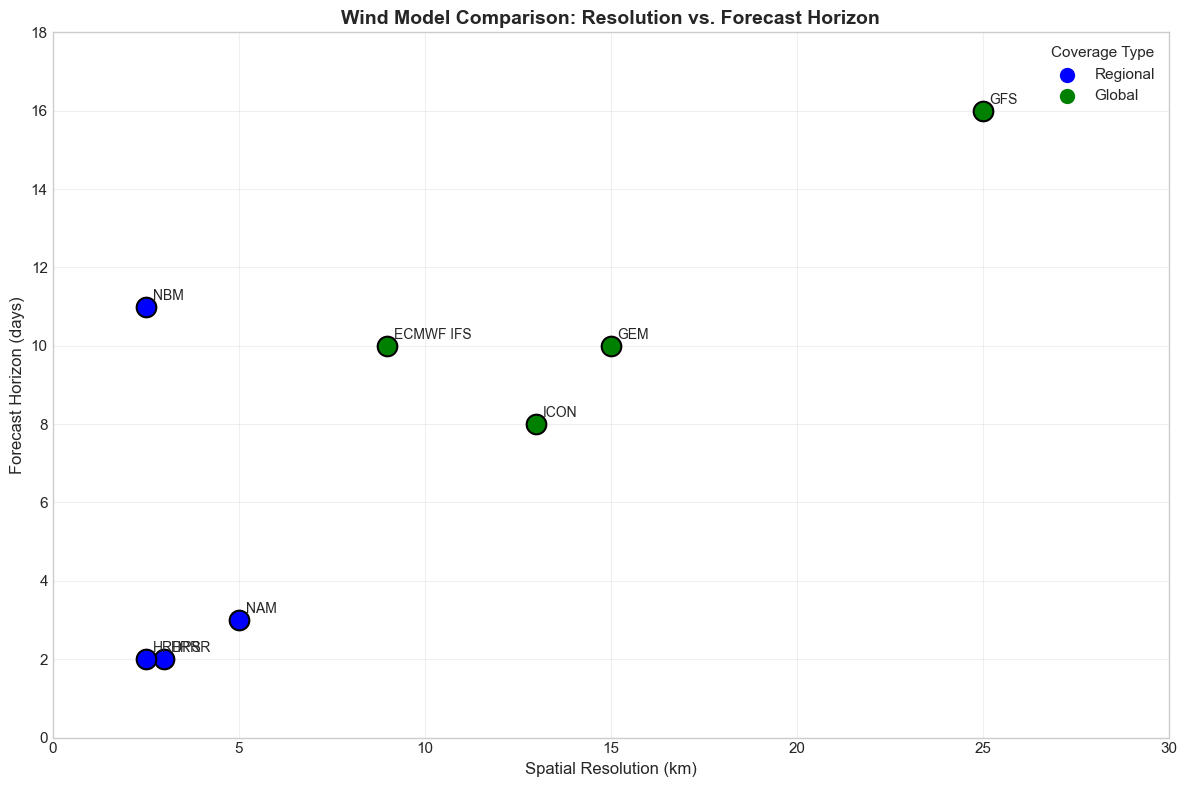

In [7]:
# Model comparison: Resolution vs Forecast Horizon
fig, ax = plt.subplots(figsize=(12, 8))

models_plot = {
    'HRRR': (3, 2, 'Regional'),
    'NAM': (5, 3, 'Regional'),
    'NBM': (2.5, 11, 'Regional'),
    'HRDPS': (2.5, 2, 'Regional'),
    'ECMWF IFS': (9, 10, 'Global'),
    'GFS': (25, 16, 'Global'),
    'ICON': (13, 8, 'Global'),
    'GEM': (15, 10, 'Global'),
}

colors = {'Regional': 'blue', 'Global': 'green'}

for model, (res, days, coverage) in models_plot.items():
    ax.scatter(res, days, s=200, c=colors[coverage], edgecolors='black', linewidths=1.5)
    ax.annotate(model, xy=(res, days), xytext=(5, 5), textcoords='offset points', fontsize=10)

ax.set_xlabel('Spatial Resolution (km)', fontsize=12)
ax.set_ylabel('Forecast Horizon (days)', fontsize=12)
ax.set_title('Wind Model Comparison: Resolution vs. Forecast Horizon', fontsize=14, fontweight='bold')
ax.set_xlim(0, 30)
ax.set_ylim(0, 18)
ax.grid(True, alpha=0.3)

handles = [plt.scatter([], [], c=c, s=100, label=l) for l, c in colors.items()]
ax.legend(handles=handles, title='Coverage Type', loc='upper right')
plt.tight_layout()
plt.show()

---
# Section 3: Data Processing Methods

## 3.1 Swell Data Processing

### Open-Meteo Marine API
```python
# API Response Structure
response = {
    "hourly": {
        "time": ["2024-01-01T00:00", ...],
        "wave_height": [1.5, ...],           # meters
        "wave_period": [8.2, ...],           # seconds
        "wave_direction": [275, ...],        # degrees
        "swell_wave_height": [1.2, ...],     # meters
        ...
    }
}
```

**Processing Steps:**
1. Parse ISO timestamp strings to datetime
2. Filter records from local date onwards
3. Direct passthrough of numeric values (no conversion needed)
4. Handle NaN/None values

### CDIP Processing
```python
# NetCDF variables
waveHs  → swell_height_m (direct)
waveTp  → swell_period_s (preferred)
waveTa  → swell_period_s (fallback if Tp missing)
waveDp  → swell_direction_deg (direct)
```

### Direction Convention
All models use **meteorological convention**: direction waves/wind are coming FROM.
- 0° = From North
- 90° = From East
- 180° = From South
- 270° = From West

---
## 3.2 Wind Data Processing

### API Response
```python
response = {
    "hourly": {
        "time": [...],
        "wind_speed_10m": [15.2, ...],      # km/h
        "wind_direction_10m": [275, ...],   # degrees
        "wind_gusts_10m": [22.5, ...]       # km/h
    }
}
```

### Unit Conversions (if needed)
- **To m/s**: ÷ 3.6
- **To knots**: × 0.539957
- **To mph**: × 0.621371

### Gust Definition
Maximum 3-second average wind speed within the forecast hour.

---
# Section 4: Results Visualization

Load and visualize the extracted forecast data.

---

In [8]:
# Configuration - Update paths to match your data files
SWELL_DATA_PATH = 'swell_forecast_results.csv'
WIND_DATA_PATH = 'wind_forecast_results.csv'

# Load swell data
try:
    swell_data = pd.read_csv(SWELL_DATA_PATH)
    swell_data['timestamp_local'] = pd.to_datetime(swell_data['timestamp_local'])
    print(f"✓ Swell data: {len(swell_data)} records, {swell_data['site_name'].nunique()} sites, {swell_data['model_key'].nunique()} models")
    SWELL_LOADED = True
except FileNotFoundError:
    print(f"⚠ Swell data not found: {SWELL_DATA_PATH}")
    print("  Run swell_forecast_extractor.py first.")
    SWELL_LOADED = False

# Load wind data
try:
    wind_data = pd.read_csv(WIND_DATA_PATH)
    wind_data['timestamp_local'] = pd.to_datetime(wind_data['timestamp_local'])
    print(f"✓ Wind data: {len(wind_data)} records, {wind_data['site_name'].nunique()} sites, {wind_data['model_key'].nunique()} models")
    WIND_LOADED = True
except FileNotFoundError:
    print(f"⚠ Wind data not found: {WIND_DATA_PATH}")
    print("  Run weather_forecast_extractor.py first.")
    WIND_LOADED = False

⚠ Swell data not found: swell_forecast_results.csv
  Run swell_forecast_extractor.py first.
✓ Wind data: 3342 records, 2 sites, 6 models


In [9]:
def plot_swell_comparison(data):
    """Swell height comparison faceted by site."""
    sites = data['site_name'].unique()
    n_sites = len(sites)
    
    fig, axes = plt.subplots(n_sites, 1, figsize=(14, 5*n_sites), sharex=True)
    if n_sites == 1:
        axes = [axes]
    
    models = data['model_key'].unique()
    colors = plt.cm.tab20(np.linspace(0, 1, len(models)))
    color_map = dict(zip(models, colors))
    
    for ax, site in zip(axes, sites):
        site_data = data[data['site_name'] == site]
        
        for model_key in models:
            model_data = site_data[site_data['model_key'] == model_key]
            if not model_data.empty and model_data['swell_height_m'].notna().any():
                display_name = model_data['model'].iloc[0]
                ax.plot(model_data['timestamp_local'], model_data['swell_height_m'],
                       label=display_name, color=color_map[model_key], linewidth=1.5, alpha=0.8)
        
        ax.set_ylabel('Swell Height (m)', fontsize=11)
        ax.set_title(f'Site: {site}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right', fontsize=8, ncol=2)
    
    axes[-1].set_xlabel('Date/Time', fontsize=11)
    fig.suptitle('Swell Height Forecast Comparison by Model', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    return fig

if SWELL_LOADED:
    fig = plot_swell_comparison(swell_data)
    plt.show()
else:
    print("Run swell_forecast_extractor.py to generate data for this plot.")

Run swell_forecast_extractor.py to generate data for this plot.


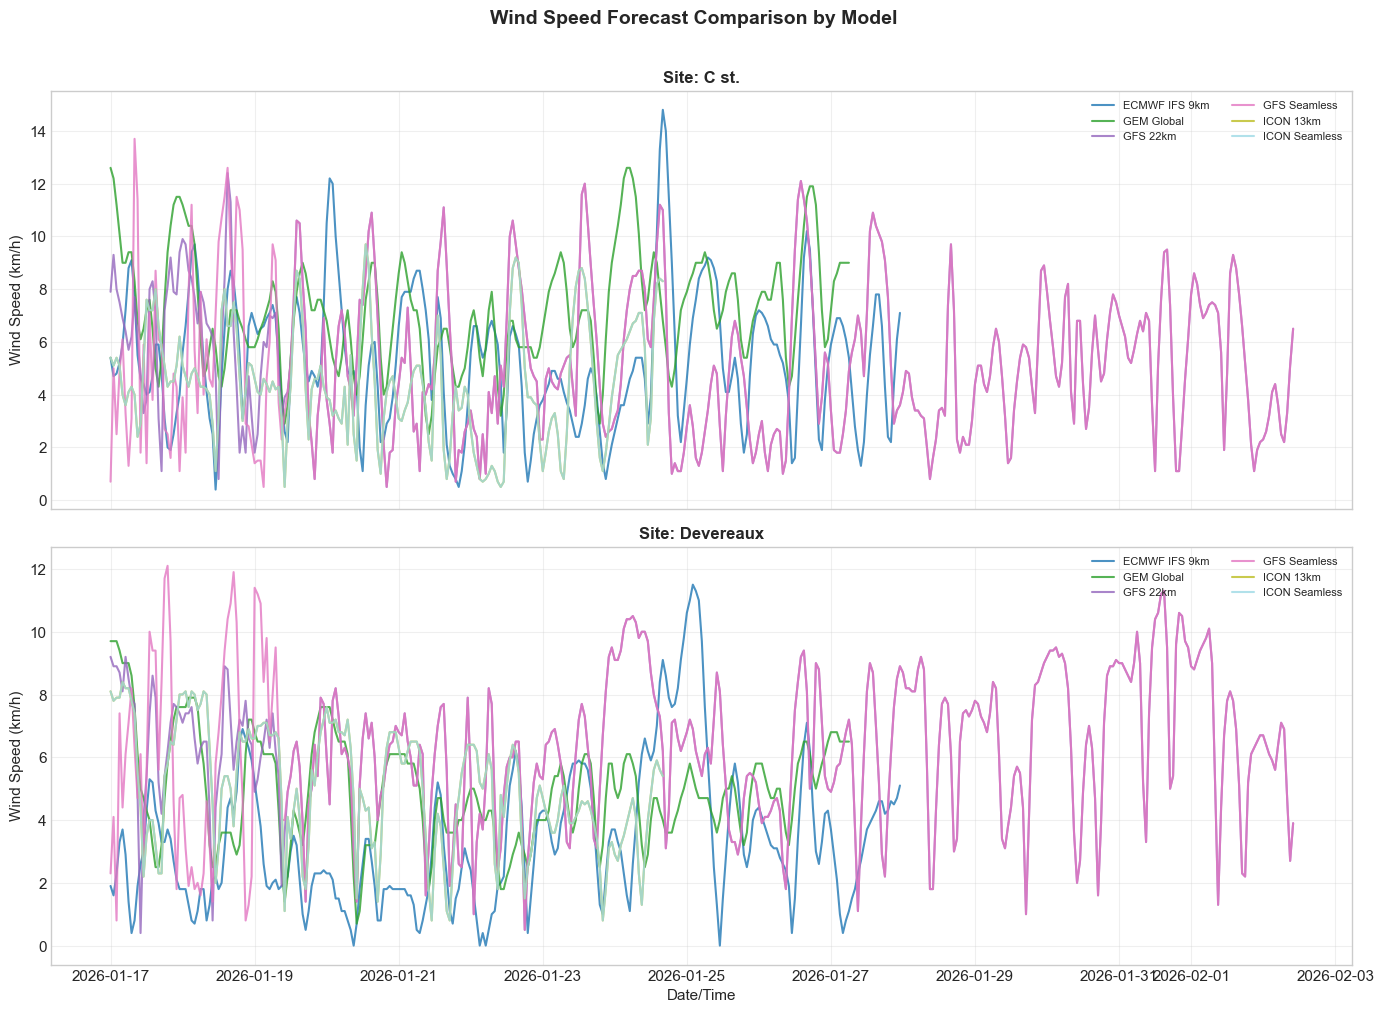

In [10]:
def plot_wind_comparison(data):
    """Wind speed comparison faceted by site."""
    sites = data['site_name'].unique()
    n_sites = len(sites)
    
    fig, axes = plt.subplots(n_sites, 1, figsize=(14, 5*n_sites), sharex=True)
    if n_sites == 1:
        axes = [axes]
    
    models = data['model_key'].unique()
    colors = plt.cm.tab20(np.linspace(0, 1, len(models)))
    color_map = dict(zip(models, colors))
    
    for ax, site in zip(axes, sites):
        site_data = data[data['site_name'] == site]
        
        for model_key in models:
            model_data = site_data[site_data['model_key'] == model_key]
            if not model_data.empty and model_data['wind_speed_10m_kmh'].notna().any():
                display_name = model_data['model'].iloc[0]
                ax.plot(model_data['timestamp_local'], model_data['wind_speed_10m_kmh'],
                       label=display_name, color=color_map[model_key], linewidth=1.5, alpha=0.8)
        
        ax.set_ylabel('Wind Speed (km/h)', fontsize=11)
        ax.set_title(f'Site: {site}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right', fontsize=8, ncol=2)
    
    axes[-1].set_xlabel('Date/Time', fontsize=11)
    fig.suptitle('Wind Speed Forecast Comparison by Model', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    return fig

if WIND_LOADED:
    fig = plot_wind_comparison(wind_data)
    plt.show()
else:
    print("Run weather_forecast_extractor.py to generate data for this plot.")

In [11]:
def plot_buoy_results_map(data):
    """Map showing buoy locations from results relative to sites."""
    buoy_data = data[data['buoy_id'].notna()].drop_duplicates(subset=['site_name', 'buoy_id'])
    
    if buoy_data.empty:
        print("No CDIP buoy data in results.")
        return None
    
    sites = data.drop_duplicates(subset=['site_name'])[['site_name', 'latitude', 'longitude']]
    
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.set_facecolor('#E6F3FF')
    
    # Plot extent
    all_lats = list(sites['latitude'])
    all_lons = list(sites['longitude'])
    
    lat_margin = max(1, (max(all_lats) - min(all_lats)) * 0.3)
    lon_margin = max(1, (max(all_lons) - min(all_lons)) * 0.3)
    
    ax.set_xlim(min(all_lons) - lon_margin, max(all_lons) + lon_margin)
    ax.set_ylim(min(all_lats) - lat_margin, max(all_lats) + lat_margin)
    
    # Plot sites
    for _, site in sites.iterrows():
        ax.plot(site['longitude'], site['latitude'], 'r*', markersize=20)
        ax.annotate(site['site_name'], xy=(site['longitude'], site['latitude']),
                   xytext=(10, 10), textcoords='offset points', fontsize=10, fontweight='bold')
    
    # Plot buoys and connections
    plotted_buoys = set()
    for _, row in buoy_data.iterrows():
        site = sites[sites['site_name'] == row['site_name']].iloc[0]
        
        # We don't have buoy lat/lon in results, so just note the distance
        ax.annotate(f"Buoy {row['buoy_id']}:\n{row['buoy_name']}\n({row['buoy_distance_km']:.1f} km)",
                   xy=(site['longitude'], site['latitude']),
                   xytext=(-80, -40), textcoords='offset points',
                   fontsize=9, color='blue',
                   bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
                   arrowprops=dict(arrowstyle='->', color='blue', alpha=0.5))
    
    ax.set_xlabel('Longitude', fontsize=12)
    ax.set_ylabel('Latitude', fontsize=12)
    ax.set_title('Site Locations and Associated CDIP Buoys', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig

if SWELL_LOADED:
    fig = plot_buoy_results_map(swell_data)
    if fig:
        plt.show()

---
# Summary

## Swell Models Summary

| Model | Resolution | Forecast | Swell Partitions | Best For |
|-------|------------|----------|------------------|----------|
| GFS Wave | 16-25 km | 16 days | 1+2+3 | Long-range, complex swells |
| MFWAM | ~8 km | 10 days | 1+2 | Medium-range |
| ECMWF WAM | 9-25 km | 15 days | 1 | Long-range |
| DWD GWAM | ~25 km | 4 days | 1 | Short-range global |
| DWD EWAM | ~5 km | 8 days | 1 | European waters |
| CDIP MOP | ~1 km | 7 days | combined | California nearshore |
| CDIP Buoys | point | 7-10 days | combined | Local validation |

## Wind Models Summary

| Model | Resolution | Forecast | Coverage | Best For |
|-------|------------|----------|----------|----------|
| HRRR | 3 km | 2 days | CONUS | Nowcasting |
| NAM | 5 km | 3 days | N. America | Short-range |
| NBM | 2.5 km | 11 days | CONUS | Blended accuracy |
| ECMWF IFS | 9 km | 10 days | Global | Medium-range |
| GFS | 25 km | 16 days | Global | Long-range |
| ICON | 13 km | 8 days | Global | European detail |
| HRDPS | 2.5 km | 2 days | Canada | Mountain terrain |

---
*Report generated from swell_forecast_extractor.py and weather_forecast_extractor.py analysis*